# user

In [1]:
VERSION = "2.0.1_sextractor"
# PSF_NAME = "psf_style-airy_size-41_pixelscale-0.1"
PSF_NAME = "psf_style-airy_size-81_pixelscale-0.06"
FILTER_NAME = "gauss_3.0_7x7.conv"
PIXEL_SCALE = 0.1

# lib

In [2]:
from pathlib import Path

from jax import numpy
from polars import DataFrame, read_csv
from tqdm import tqdm
import numpy as np

from utils import (
    ldac,
    gauss_conv,
    hdul_object_ldac,
    extra_psf_images,
    extra_psf_images_reshaped,
    image_fitting,
    case_result,
    histos,
    ellips_se,
    ellips_model,
    case_result_param,
    delete_duplicate,
    search_folder,
    tfds_info,
    slice_csv,
    # background,
)

DATASETS_PSF_DIR = Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/psf")
DATASET_DIR = Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid") / VERSION
RESULTS_SEXTRACTOR_DIR = Path("/net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR")
PSF_DIR = RESULTS_SEXTRACTOR_DIR / PSF_NAME
RESULTS_DIR = RESULTS_SEXTRACTOR_DIR / VERSION
CATALOG_DIR = RESULTS_DIR / "CATALOG"
IMAGES_DIR = RESULTS_DIR / "IMAGES"
PLOTS_DIR = RESULTS_DIR / "PLOTS"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# info databases

In [3]:
info = tfds_info(
    style="pisco_euclid",
    version=VERSION,
    data_dir=search_folder(name="DATASETS"),
)

for key, value in info.release_notes.items():
    print(f"{key}: {value}")

2.1.2: 100_000 (50_000 + 50_000 shape noise cancellation)
2.0.2: 2_000 (1000 + 1000 shape noise cancellation) 
2.1.1: 50_000
2.0.1: 1_000
2.*.*: lhs + g round(2) + 10 gal/patch + g<|0.05| + e gauss + seeds 22 & 2222 + airy


# filter

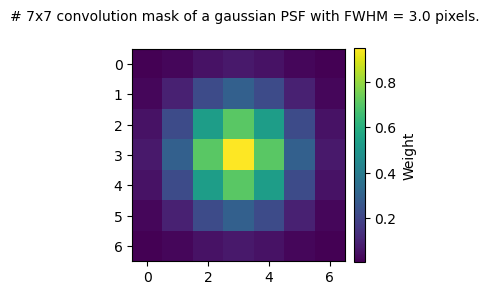

In [4]:
gauss_conv(DATASETS_PSF_DIR / FILTER_NAME, PLOTS_DIR)

# ldac

In [5]:
objects_data = ldac(PSF_DIR, PSF_NAME)

Filename: /net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR/psf_style-airy_size-81_pixelscale-0.06/psf_style-airy_size-81_pixelscale-0.06.ldac
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  LDAC_IMHEAD    1 BinTableHDU     12   1R x 1C   [4240A]   
  2  LDAC_OBJECTS    1 BinTableHDU     89   1R x 21C   [1J, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1E, 1I, 1I, 1681E, 1E, 1E, 1J, 1E, 1E, 1D, 1D]   

=== LDAC_IMHEAD (HDU[1]) ===
Row 1: (chararray(['SIMPLE  =                    T / conforms to FITS standard',
           'BITPIX  =                  -32 / array data type',
           'NAXIS   =                    2 / number of array dimensions',
           'NAXIS1  =                   81',
           'NAXIS2  =                   81',
           'EXTEND  =                    T',
           "FITSFILE= 'psf_style-airy_size-81_pixelscale-0.06.fits' / File name of the analy",
           'FITSEXT =                    1 / FITS Extension n

NUMBER 1
SNR_WIN 1.396472454071045
FLUX_RADIUS 1.3317517042160034
FLUX_MAX 0.16410145163536072
FLUX_AUTO 0.949205219745636
FLUXERR_AUTO 0.5533491373062134
FLUX_APER 0.896404504776001
FLUXERR_APER 0.537738561630249
X_IMAGE 41.0
Y_IMAGE 41.0
ELONGATION 1.000000238418579
FLAGS 0
FLAGS_WEIGHT 0
FWHM_IMAGE 1.8283345699310303
MAG_AUTO 30.8966007232666
ISOAREA_IMAGE 2301
ISOAREA_WORLD 1.7754630334820831e-06
MU_MAX 27.80221939086914
X_WORLD 40.00000007235064
Y_WORLD 39.99999997152064


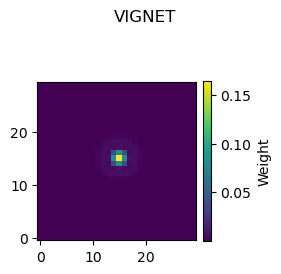

In [6]:
shape_vignet = hdul_object_ldac(objects_data, PLOTS_DIR)

# extra images psf

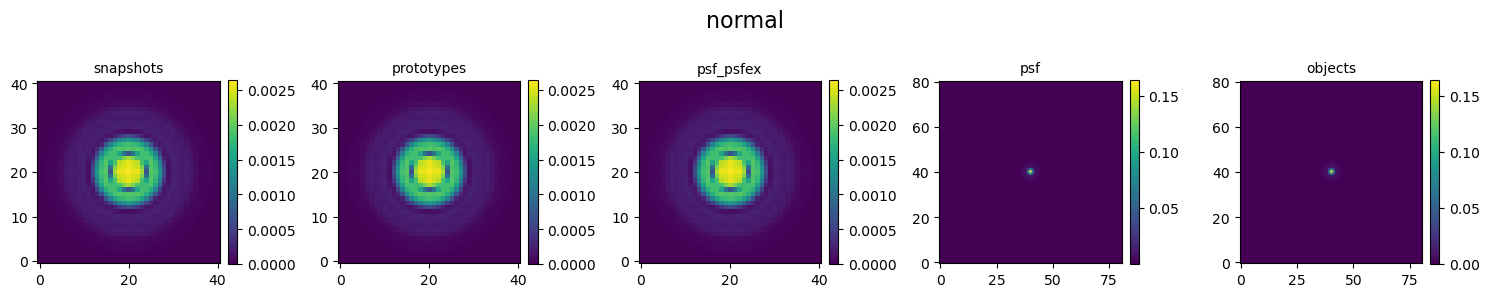

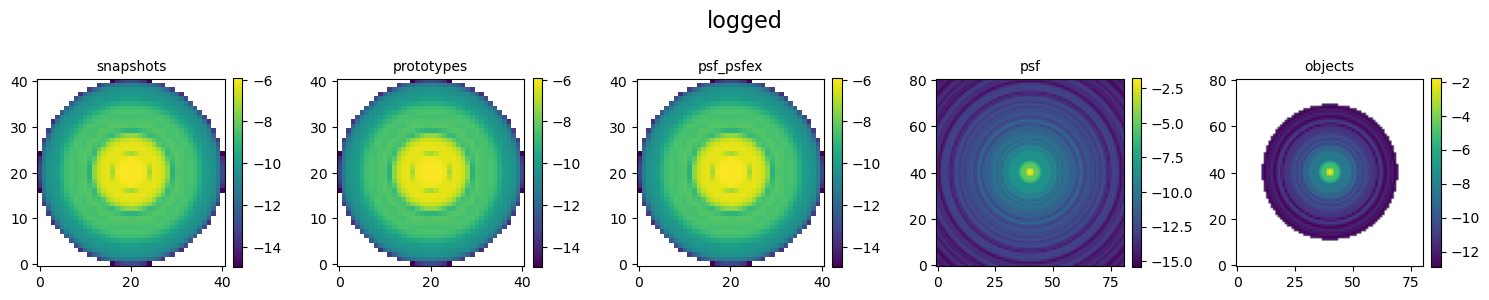

In [7]:
extra_psf_images(DATASETS_PSF_DIR, PSF_NAME, PSF_DIR, PLOTS_DIR, loggy=False)
extra_psf_images(DATASETS_PSF_DIR, PSF_NAME, PSF_DIR, PLOTS_DIR, loggy=True)

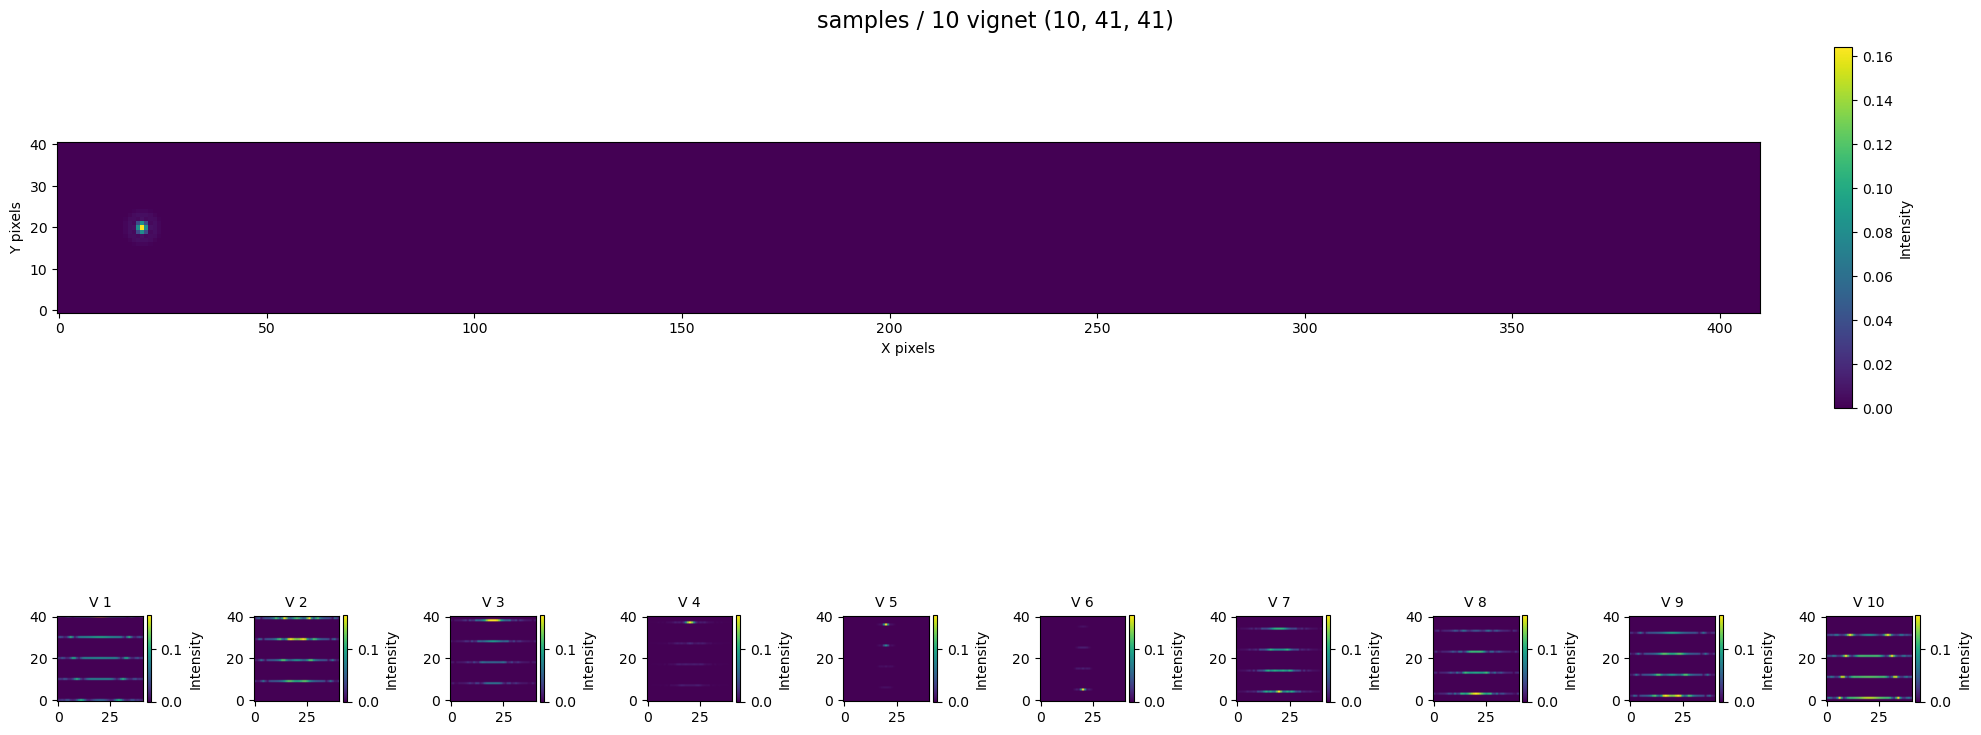

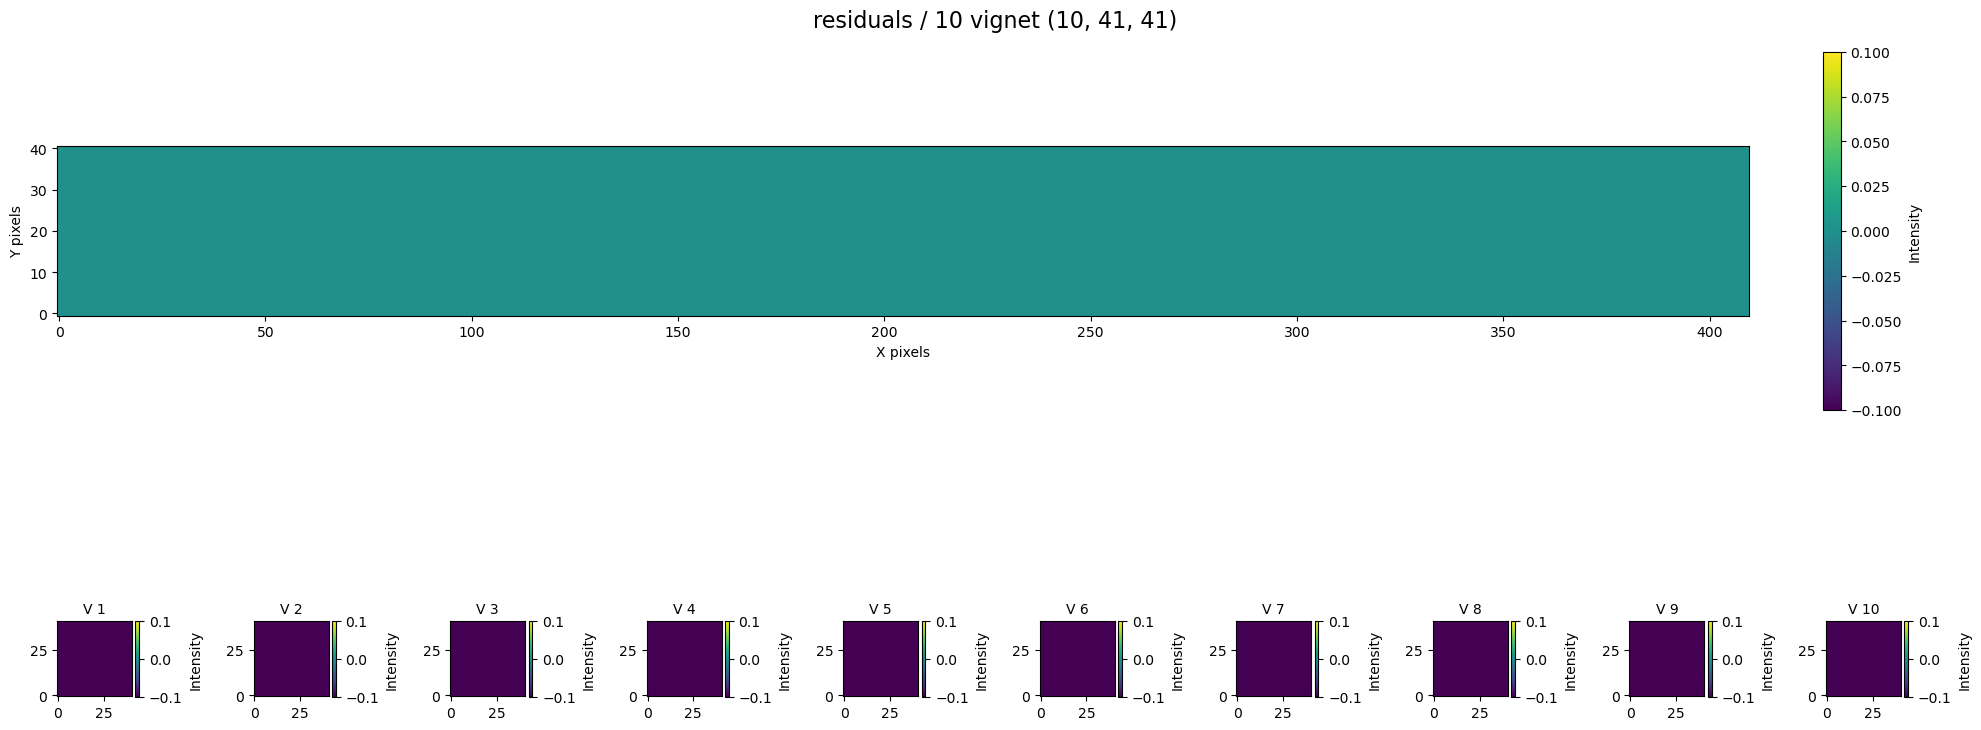

In [8]:
extra_psf_images_reshaped(PSF_DIR, PSF_NAME, shape_vignet, PLOTS_DIR, style="samples")
extra_psf_images_reshaped(PSF_DIR, PSF_NAME, shape_vignet, PLOTS_DIR, style="residuals")

# extra

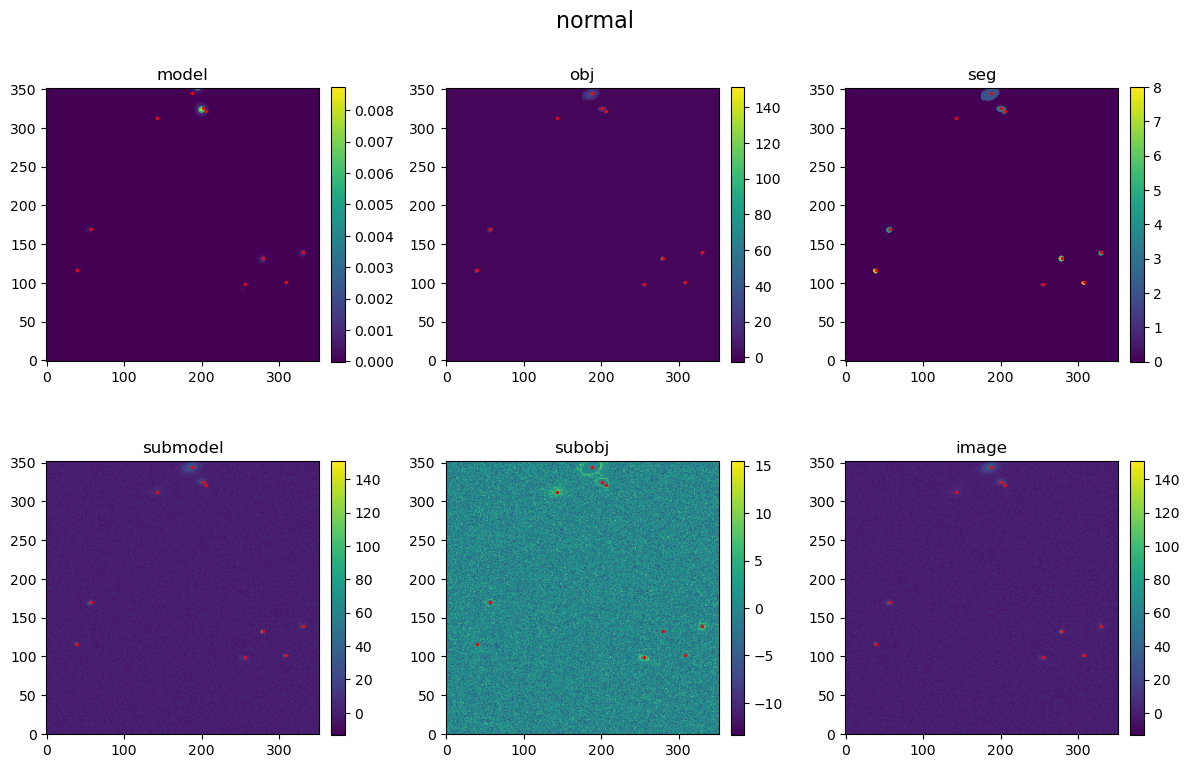

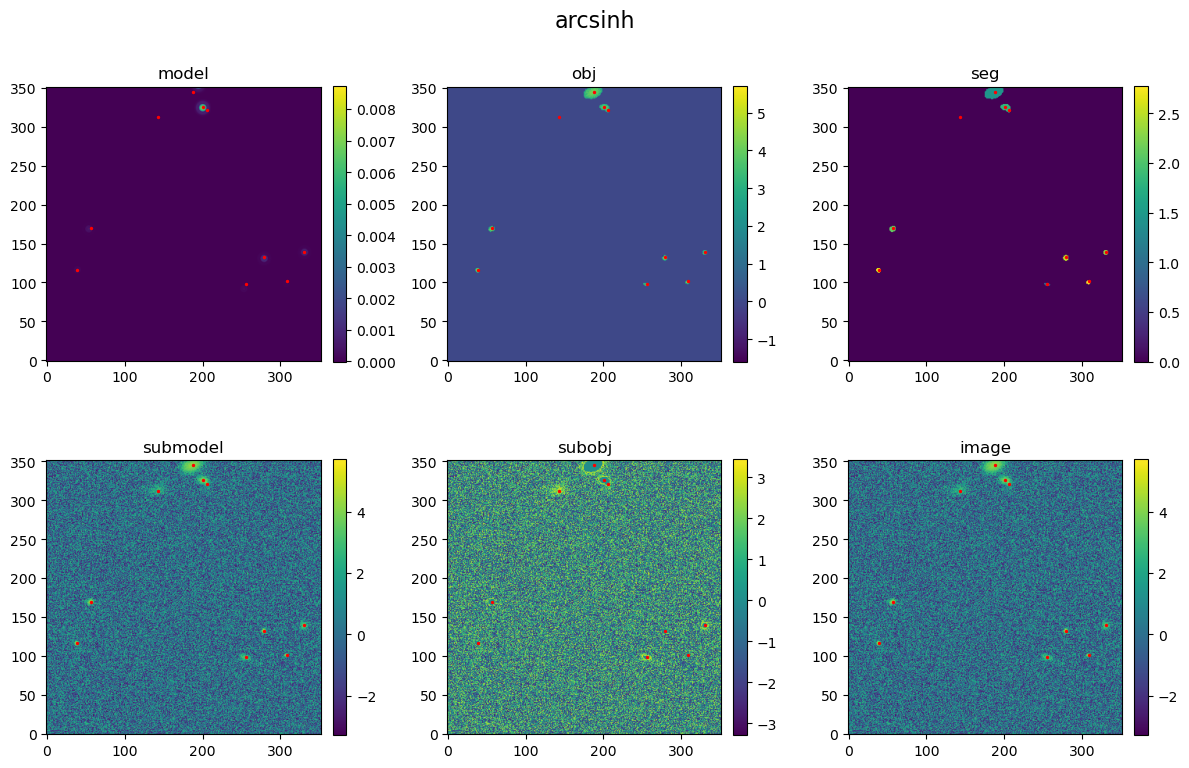

In [9]:
CHOICE = "000003_simu"
image_fitting(DATASET_DIR, IMAGES_DIR, CHOICE, PLOTS_DIR)
image_fitting(DATASET_DIR, IMAGES_DIR, CHOICE, PLOTS_DIR, transformed=True)

# inference

In [ ]:
PRED_FILES = sorted(list((CATALOG_DIR).glob("*_simu.csv")))
TRUE_FILES = sorted(list((DATASET_DIR).glob("*_true_galaxies_params.csv")))
TOTAL = len(PRED_FILES)
true_images_params = slice_csv(DATASET_DIR / "true_images_params.csv", TOTAL)
true_avg_g = true_images_params[["avg_g1", "avg_g2"]].to_numpy()
true_avg_g

In [ ]:
g1_bin_obs = [[] for _ in range(11)]
g2_bin_obs = [[] for _ in range(11)]


In [ ]:
g1_bin_obs

In [ ]:
KK = 0
for result_file, true_file, values in tqdm(zip(PRED_FILES, TRUE_FILES, true_avg_g), total=TOTAL):
    df_pred = read_csv(result_file).sort("X_IMAGE")
    df_true = read_csv(true_file).sort("x")

    obs_e1_se, obs_e2_se = ellips_se(df_pred["ELLIPTICITY"], df_pred["THETA_IMAGE"])

    g1, g2 = values
    print(g1, g2)

    KK += 1
    if KK > 4:
        break

In [ ]:
bins = np.round(np.arange(-0.05, 0.051, 0.01), decimals=2)
bins

In [ ]:
bin_to_index = {v: i for i, v in enumerate(bins)}
bin_to_index

In [ ]:
for result_file, true_file, values in tqdm(zip(PRED_FILES, TRUE_FILES, true_avg_g), total=TOTAL):
    x, y = values
    print(x, y)

In [ ]:
PRED_FILES = sorted(list((CATALOG_DIR).glob("*_simu.csv")))
TRUE_FILES = sorted(list((DATASET_DIR).glob("*_true_galaxies_params.csv")))

all_obs_e1_model_err, all_obs_e2_model_err, all_obs_e1_model, all_obs_e2_model = [], [], [], []
all_obs_ell_se, all_obs_theta_se = [], []
avg_obs_e1_model, avg_obs_e2_model, avg_obs_e1_se, avg_obs_e2_se = [], [], [], []

mag, mag_err, sersic, sersic_err, hlr, true_mag, true_hlr, true_sersic = [[] for _ in range(8)]
slice_sersic, slice_sersic_err, slice_mag, slice_mag_err, slice_hlr = [[] for _ in range(5)]
slice_true_hlr, slice_true_mag, slice_true_sersic = [[] for _ in range(3)]
detections = []

TOTAL = len(PRED_FILES)
for result_file, true_file in tqdm(zip(PRED_FILES, TRUE_FILES), total=TOTAL):
    df_pred = read_csv(result_file).sort("X_IMAGE")
    df_true = read_csv(true_file).sort("x")

    obs_e1_se, obs_e2_se = ellips_se(df_pred["ELLIPTICITY"], df_pred["THETA_IMAGE"])
    avg_obs_e1_se.append(obs_e1_se)
    avg_obs_e2_se.append(obs_e2_se)

    all_obs_ell_se.append(df_pred["ELLIPTICITY"].to_numpy())
    all_obs_theta_se.append(df_pred["THETA_IMAGE"].to_numpy())

    obs_e1_model, obs_e2_model = ellips_model(
        df_pred["ELLIP1ERRMODEL_IMAGE"],
        df_pred["ELLIP2ERRMODEL_IMAGE"],
        df_pred["ELLIP1MODEL_IMAGE"],
        df_pred["ELLIP2MODEL_IMAGE"],
    )
    avg_obs_e1_model.append(obs_e1_model)
    avg_obs_e2_model.append(obs_e2_model)

    all_obs_e1_model.append(df_pred["ELLIP1MODEL_IMAGE"].to_numpy())
    all_obs_e2_model.append(df_pred["ELLIP2MODEL_IMAGE"].to_numpy())
    all_obs_e1_model_err.append(df_pred["ELLIP1ERRMODEL_IMAGE"].to_numpy())
    all_obs_e2_model_err.append(df_pred["ELLIP2ERRMODEL_IMAGE"].to_numpy())

    mag.append(df_pred["MAG_AUTO"].to_numpy())
    mag_err.append(df_pred["MAGERR_AUTO"].to_numpy())

    sersic.append(df_pred["SPHEROID_SERSICN"].to_numpy())
    sersic_err.append(df_pred["SPHEROID_SERSICNERR"].to_numpy())

    hlr.append(df_pred["FLUX_RADIUS"].to_numpy())

    true_mag.append(df_true["mag"].to_numpy())
    true_sersic.append(df_true["sersic"].to_numpy())
    true_hlr.append(df_true["hlr"].to_numpy())

    NUMBER_DETECTED = df_pred.shape[0]
    detections.append(NUMBER_DETECTED)

    if NUMBER_DETECTED != 10:
        df_pred = delete_duplicate(df_pred)
        df_true = df_true.filter(df_true["x"].is_in(df_pred["assoc1"]))
        assert df_pred.shape[0] == df_true.shape[0]

    slice_mag.append(df_pred["MAG_AUTO"].to_numpy())
    slice_mag_err.append(df_pred["MAGERR_AUTO"].to_numpy())

    slice_sersic.append(df_pred["SPHEROID_SERSICN"].to_numpy())
    slice_sersic_err.append(df_pred["SPHEROID_SERSICNERR"].to_numpy())

    slice_hlr.append(df_pred["FLUX_RADIUS"].to_numpy())

    slice_true_mag.append(df_true["mag"].to_numpy())
    slice_true_sersic.append(df_true["sersic"].to_numpy())
    slice_true_hlr.append(df_true["hlr"].to_numpy())

detections = numpy.array(detections)

all_obs_ell_se = numpy.concatenate(all_obs_ell_se)
all_obs_theta_se = numpy.concatenate(all_obs_theta_se)
all_obs_e1_model = numpy.concatenate(all_obs_e1_model)
all_obs_e2_model = numpy.concatenate(all_obs_e2_model)
all_obs_e1_model_err = numpy.concatenate(all_obs_e1_model_err)
all_obs_e2_model_err = numpy.concatenate(all_obs_e2_model_err)

sersic = numpy.concatenate(sersic)
sersic_err = numpy.concatenate(sersic_err)
true_sersic = numpy.concatenate(true_sersic)
slice_sersic = numpy.concatenate(slice_sersic)
slice_sersic_err = numpy.concatenate(slice_sersic_err)
slice_true_sersic = numpy.concatenate(slice_true_sersic)

mag = numpy.concatenate(mag)
mag_err = numpy.concatenate(mag_err)
true_mag = numpy.concatenate(true_mag)
slice_mag = numpy.concatenate(slice_mag)
slice_mag_err = numpy.concatenate(slice_mag_err)
slice_true_mag = numpy.concatenate(slice_true_mag)

hlr = numpy.concatenate(hlr)
true_hlr = numpy.concatenate(true_hlr)
slice_hlr = numpy.concatenate(slice_hlr)
slice_true_hlr = numpy.concatenate(slice_true_hlr)

loss_comp = round(((sersic.shape[0] - slice_sersic.shape[0]) / sersic.shape[0]) * 100, 2)
loss_gal = round(((sersic.shape[0]) / true_sersic.shape[0]) * 100, 2)

DataFrame(
    data={
        "avg_obs_e1_se": avg_obs_e1_se,
        "avg_obs_e2_se": avg_obs_e2_se,
        "avg_obs_e1_model": avg_obs_e1_model,
        "avg_obs_e2_model": avg_obs_e2_model,
    },
).write_csv(file=RESULTS_DIR / "pred_avg_obs_e.csv")

print("normal", sersic.shape[0], sersic_err.shape[0], true_sersic.shape[0])
print("slice", slice_sersic.shape[0], slice_sersic_err.shape[0], slice_true_sersic.shape[0])

del (
    df_pred,
    df_true,
    NUMBER_DETECTED,
    avg_obs_e1_model,
    avg_obs_e2_model,
    avg_obs_e1_se,
    avg_obs_e2_se,
    obs_e1_model,
    obs_e1_se,
    obs_e2_model,
    obs_e2_se,
    PRED_FILES,
    TRUE_FILES,
)

# loading params

In [ ]:
true_images_params = slice_csv(DATASET_DIR / "true_images_params.csv", TOTAL)
true_avg_obs_e = true_images_params[["avg_obs_e1", "avg_obs_e2"]].to_numpy()
true_avg_int_e = true_images_params[["avg_int_e1", "avg_int_e2"]].to_numpy()
true_avg_g = true_images_params[["avg_g1", "avg_g2"]].to_numpy()

pred_avg_obs_e = slice_csv(RESULTS_DIR / "pred_avg_obs_e.csv", TOTAL)
sex_pred_obs_e = pred_avg_obs_e[["avg_obs_e1_se", "avg_obs_e2_se"]].to_numpy()
model_pred_obs_e = pred_avg_obs_e[["avg_obs_e1_model", "avg_obs_e2_model"]].to_numpy()

print(true_avg_obs_e.shape, true_avg_int_e.shape, true_avg_g.shape, pred_avg_obs_e.shape)
del pred_avg_obs_e, true_images_params

# histo

In [ ]:
bins = 50
loggy = False
histos(
    detections,
    sersic,
    sersic_err,
    true_sersic,
    mag,
    mag_err,
    true_mag,
    hlr,
    true_hlr,
    sex_pred_obs_e,
    model_pred_obs_e,
    true_avg_obs_e,
    PLOTS_DIR,
    PIXEL_SCALE,
    bins=bins,
    loggy=loggy,
)

# results

In [ ]:
case_result(true_avg_obs_e, true_avg_g, PLOTS_DIR / "results_ell_best.pdf")
case_result(sex_pred_obs_e, true_avg_g, PLOTS_DIR / "results_ell_internal.pdf")
case_result(model_pred_obs_e, true_avg_g, PLOTS_DIR / "results_ell_model.pdf")

# results by params

In [ ]:
case_result_param(
    slice_mag, slice_true_mag, loss_comp, loss_gal, PLOTS_DIR, symbol="mag", err=slice_mag_err
)
case_result_param(
    slice_hlr, slice_true_hlr, loss_comp, loss_gal, PLOTS_DIR, symbol="hlr", pixel_scale=PIXEL_SCALE
)
case_result_param(
    slice_sersic,
    slice_true_sersic,
    loss_comp,
    loss_gal,
    PLOTS_DIR,
    symbol="sersic",
    err=slice_sersic_err,
)